In [1]:
import os
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

spark = SparkSession.builder.master("local[*]").appName("ews-model").getOrCreate()
cat_cols = ["code_module", "gender", "region", "highest_education",
            "imd_band", "age_band", "disability"]
meta = set(cat_cols + ["id_student", "code_presentation", "at_risk", "split"])

def evaluate(cutoff):
    df = spark.read.parquet(f"../data/processed/features_day{cutoff}.parquet")
    num_cols = [c for c in df.columns if c not in meta]
    train, test = df.filter("split = 'train'"), df.filter("split = 'test'")
    idx = StringIndexer(inputCols=cat_cols, outputCols=[c + "_i" for c in cat_cols], handleInvalid="keep")
    ohe = OneHotEncoder(inputCols=[c + "_i" for c in cat_cols], outputCols=[c + "_v" for c in cat_cols])
    vec = VectorAssembler(inputCols=num_cols + [c + "_v" for c in cat_cols], outputCol="features")
    rows = []
    for name, clf in [("LogReg", LogisticRegression(labelCol="at_risk", maxIter=100)),
                      ("RandForest", RandomForestClassifier(labelCol="at_risk", numTrees=200, maxDepth=8, seed=42))]:
        p = Pipeline(stages=[idx, ohe, vec, clf]).fit(train).transform(test)
        auc = BinaryClassificationEvaluator(labelCol="at_risk", metricName="areaUnderROC").evaluate(p)
        tp = p.filter("at_risk = 1 AND prediction = 1").count()
        fp = p.filter("at_risk = 0 AND prediction = 1").count()
        fn = p.filter("at_risk = 1 AND prediction = 0").count()
        pr, rc = tp / (tp + fp), tp / (tp + fn)
        rows.append(dict(cutoff=cutoff, model=name, auc=auc, precision=pr, recall=rc, f1=2 * pr * rc / (pr + rc)))
    return rows

results = pd.DataFrame([r for c in [28, 56, 84] for r in evaluate(c)])
os.makedirs("../reports", exist_ok=True)
results.to_csv("../reports/results_by_cutoff.csv", index=False)
results.round(3)

,cutoff,model,auc,precision,recall,f1
0,28,LogReg,0.768,0.706,0.554,0.621
1,28,RandForest,0.772,0.742,0.511,0.605
2,56,LogReg,0.812,0.756,0.589,0.662
3,56,RandForest,0.808,0.793,0.537,0.641
4,84,LogReg,0.834,0.769,0.597,0.673
5,84,RandForest,0.836,0.842,0.532,0.652


In [2]:
import numpy as np
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

def scores(model, d):
    return (model.transform(d).withColumn("p", vector_to_array("probability")[1])
            .select("at_risk", "p").toPandas())

def at_threshold(s, t):
    pred = s.p >= t
    tp = ((s.at_risk == 1) & pred).sum()
    fp = ((s.at_risk == 0) & pred).sum()
    fn = ((s.at_risk == 1) & ~pred).sum()
    return tp / (tp + fp), tp / (tp + fn)

TARGET = 0.75
grid = np.arange(0.05, 0.96, 0.01)
rows = []
for cutoff in [28, 56, 84]:
    df = spark.read.parquet(f"../data/processed/features_day{cutoff}.parquet")
    num_cols = [c for c in df.columns if c not in meta]
    train, test = df.filter("split = 'train'"), df.filter("split = 'test'")
    is_val = F.pmod(F.hash("id_student", F.lit("val")), F.lit(5)) == 0
    tr, val = train.filter(~is_val), train.filter(is_val)

    idx = StringIndexer(inputCols=cat_cols, outputCols=[c + "_i" for c in cat_cols], handleInvalid="keep")
    ohe = OneHotEncoder(inputCols=[c + "_i" for c in cat_cols], outputCols=[c + "_v" for c in cat_cols])
    vec = VectorAssembler(inputCols=num_cols + [c + "_v" for c in cat_cols], outputCol="features")
    model = Pipeline(stages=[idx, ohe, vec, LogisticRegression(labelCol="at_risk", maxIter=100)]).fit(tr)

    sv, st = scores(model, val), scores(model, test)
    ok = [t for t in grid if at_threshold(sv, t)[1] >= TARGET]
    t = max(ok) if ok else grid[0]
    pr, rc = at_threshold(st, t)
    rows.append(dict(cutoff=cutoff, threshold=round(float(t), 2),
                     test_precision=round(float(pr), 3), test_recall=round(float(rc), 3)))

pd.DataFrame(rows)

,cutoff,threshold,test_precision,test_recall
0,28,0.38,0.622,0.739
1,56,0.37,0.655,0.739
2,84,0.36,0.676,0.728


In [3]:
rows = []
for cutoff in [28, 56, 84]:
    df = spark.read.parquet(f"../data/processed/features_day{cutoff}.parquet")
    num_cols = [c for c in df.columns if c not in meta]

    old = df.filter(F.col("code_presentation").startswith("2013"))   # learn from the past
    new = df.filter(F.col("code_presentation").startswith("2014"))   # predict the "future"
    is_val = F.pmod(F.hash("id_student", F.lit("val")), F.lit(5)) == 0
    tr, val = old.filter(~is_val), old.filter(is_val)

    idx = StringIndexer(inputCols=cat_cols, outputCols=[c + "_i" for c in cat_cols], handleInvalid="keep")
    ohe = OneHotEncoder(inputCols=[c + "_i" for c in cat_cols], outputCols=[c + "_v" for c in cat_cols])
    vec = VectorAssembler(inputCols=num_cols + [c + "_v" for c in cat_cols], outputCol="features")
    model = Pipeline(stages=[idx, ohe, vec,
                             LogisticRegression(labelCol="at_risk", maxIter=100)]).fit(tr)

    auc = BinaryClassificationEvaluator(labelCol="at_risk",
                                        metricName="areaUnderROC").evaluate(model.transform(new))
    sv, sn = scores(model, val), scores(model, new)
    ok = [t for t in grid if at_threshold(sv, t)[1] >= TARGET]
    t = max(ok) if ok else grid[0]
    pr, rc = at_threshold(sn, t)
    rows.append(dict(cutoff=cutoff, train_n=tr.count(), test_n=new.count(),
                     auc_2014=round(auc, 3), threshold=round(float(t), 2),
                     precision=round(float(pr), 3), recall=round(float(rc), 3)))

pd.DataFrame(rows)

,cutoff,train_n,test_n,auc_2014,threshold,precision,recall
0,28,9430,15729,0.753,0.39,0.633,0.713
1,56,9139,15092,0.806,0.36,0.646,0.741
2,84,8911,14590,0.829,0.35,0.644,0.766


In [ ]:
pd.DataFrame(rows).to_csv("../reports/results_2013_to_2014.csv", index=False)

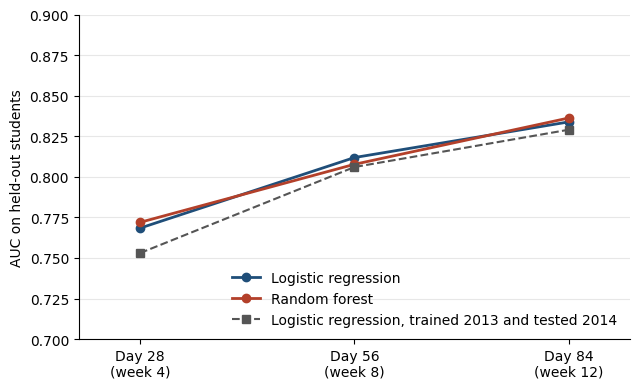

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

r = pd.read_csv("../reports/results_by_cutoff.csv")
fig, ax = plt.subplots(figsize=(6.5, 4))

for model, colour in [("LogReg", "#1f4e79"), ("RandForest", "#b3402a")]:
    d = r[r.model == model].sort_values("cutoff")
    ax.plot(d.cutoff, d.auc, marker="o", linewidth=2, color=colour,
            label="Logistic regression" if model == "LogReg" else "Random forest")

# optional: the 2013-to-2014 results, if you saved them earlier
f = "../reports/results_2013_to_2014.csv"
if os.path.exists(f):
    t = pd.read_csv(f).sort_values("cutoff")
    ax.plot(t.cutoff, t.auc_2014, marker="s", linestyle="--", color="#555555",
            label="Logistic regression, trained 2013 and tested 2014")

ax.set_xticks([28, 56, 84])
ax.set_xticklabels(["Day 28\n(week 4)", "Day 56\n(week 8)", "Day 84\n(week 12)"])
ax.set_ylabel("AUC on held-out students")
ax.set_ylim(0.70, 0.90)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="lower right")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)

ax.set_xlim(20, 92)
fig.tight_layout()
fig.savefig("../reports/fig1_auc_by_checkpoint.png", dpi=200)
plt.show()